# Linear Regression Stock Price Prediction Model

This notebook implements basic linear regression models for stock price prediction using the features engineered in the previous notebook.

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported for Linear Regression modeling!")

Libraries imported for Linear Regression modeling!


In [2]:
# Load preprocessed data from previous notebook
# We'll recreate the enhanced data here for demonstration
import os

# Data loading and preprocessing functions
data_path = r"e:\Modelling\Project\Data -Working"

stock_files = {
    'BAJAJ': 'BAJAJ-Historical-Data.csv',
    'HDFC_BANK': 'HDFCBank-Historical-Data.csv',
    'HINDALCO': 'Hindalco-Historical-Data.csv',
    'HUL': 'HUL-Historical-Data.csv',
    'ICICI_BANK': 'ICICIBank-Historical-Data.csv',
    'INFOSYS': 'Infosys-Historical- Data.csv',
    'ITC': 'ITC-Historical-Data.csv',
    'LT': 'L&T-Historical-Data.csv',
    'NIFTY50': 'Nifty-50-Historical-Data.csv',
    'RELIANCE': 'RelianceIndustries-Historical-Data.csv',
    'SBI': 'SBI-Historical-Data.csv',
    'TATA_MOTORS': 'TATAMotors-Historical-Data.csv',
    'TATA_STEEL': 'TataSteel-Historical-Data.csv',
    'TCS': 'TCS-Historical-Data.csv'
}

def convert_volume(vol_str):
    try:
        vol_str = str(vol_str).strip()
        if vol_str.endswith('M'):
            return float(vol_str[:-1]) * 1_000_000
        elif vol_str.endswith('K'):
            return float(vol_str[:-1]) * 1_000
        else:
            return float(vol_str)
    except:
        return np.nan

def load_stock_data(file_path):
    try:
        df = pd.read_csv(file_path)
        df.columns = df.columns.str.replace('"', '')
        df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
        
        numeric_columns = ['Price', 'Open', 'High', 'Low']
        for col in numeric_columns:
            if col in df.columns:
                df[col] = df[col].astype(str).str.replace(',', '').astype(float)
        
        if 'Vol.' in df.columns:
            df['Volume'] = df['Vol.'].astype(str).str.replace(',', '')
            df['Volume'] = df['Volume'].apply(convert_volume)
            df = df.drop('Vol.', axis=1)
        
        if 'Change %' in df.columns:
            df['Change_Pct'] = df['Change %'].astype(str).str.replace('%', '').astype(float)
            df = df.drop('Change %', axis=1)
        
        df = df.sort_values('Date').reset_index(drop=True)
        return df
    except Exception as e:
        print(f"Error loading {file_path}: {str(e)}")
        return None

print("Data loading functions recreated!")

Data loading functions recreated!


In [3]:
# Load and prepare TCS data for modeling
print("Loading TCS data for linear regression modeling...")

# Load TCS data
tcs_file = os.path.join(data_path, stock_files['TCS'])
tcs_data = load_stock_data(tcs_file)

print(f"TCS data loaded: {len(tcs_data)} records")
print(f"Date range: {tcs_data['Date'].min()} to {tcs_data['Date'].max()}")

# Add basic features for prediction
def add_basic_features(df):
    df = df.copy()
    
    # Price-based features
    df['Price_Lag_1'] = df['Price'].shift(1)
    df['Price_Lag_2'] = df['Price'].shift(2)
    df['Price_Lag_3'] = df['Price'].shift(3)
    
    # Moving averages
    df['SMA_5'] = df['Price'].rolling(window=5).mean()
    df['SMA_10'] = df['Price'].rolling(window=10).mean()
    df['SMA_20'] = df['Price'].rolling(window=20).mean()
    
    # Price momentum
    df['Price_Change_1'] = df['Price'].pct_change(1)
    df['Price_Change_5'] = df['Price'].pct_change(5)
    df['Price_Change_10'] = df['Price'].pct_change(10)
    
    # Technical indicators
    df['High_Low_Range'] = df['High'] - df['Low']
    df['Open_Close_Range'] = abs(df['Price'] - df['Open'])
    
    # Volume features (if available)
    if 'Volume' in df.columns:
        df['Volume_MA_5'] = df['Volume'].rolling(window=5).mean()
        df['Volume_Ratio'] = df['Volume'] / df['Volume_MA_5']
    
    # RSI-like indicator (simplified)
    delta = df['Price'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    df['RSI'] = 100 - (100 / (1 + rs))
    
    # Target variable: Next day price
    df['Target_Price'] = df['Price'].shift(-1)
    
    return df

# Apply feature engineering
tcs_enhanced = add_basic_features(tcs_data)
print(f"Features added. Total columns: {len(tcs_enhanced.columns)}")
print(f"Feature columns: {list(tcs_enhanced.columns)}")

Loading TCS data for linear regression modeling...
TCS data loaded: 2665 records
Date range: 2015-01-01 00:00:00 to 2025-10-03 00:00:00
Features added. Total columns: 22
Feature columns: ['Date', 'Price', 'Open', 'High', 'Low', 'Volume', 'Change_Pct', 'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3', 'SMA_5', 'SMA_10', 'SMA_20', 'Price_Change_1', 'Price_Change_5', 'Price_Change_10', 'High_Low_Range', 'Open_Close_Range', 'Volume_MA_5', 'Volume_Ratio', 'RSI', 'Target_Price']


In [4]:
# Prepare data for modeling
print("Preparing data for linear regression modeling...")

# Select features for modeling (exclude Date and target)
feature_columns = [
    'Price_Lag_1', 'Price_Lag_2', 'Price_Lag_3',
    'SMA_5', 'SMA_10', 'SMA_20',
    'Price_Change_1', 'Price_Change_5', 'Price_Change_10',
    'High_Low_Range', 'Open_Close_Range',
    'Volume', 'Volume_Ratio', 'RSI'
]

# Remove rows with NaN values (due to lags and rolling windows)
modeling_data = tcs_enhanced.dropna()
print(f"Data after removing NaN: {len(modeling_data)} records")

# Prepare X (features) and y (target)
X = modeling_data[feature_columns]
y = modeling_data['Target_Price']

print(f"Feature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

# Check for any remaining NaN values
print(f"NaN values in features: {X.isnull().sum().sum()}")
print(f"NaN values in target: {y.isnull().sum()}")

# Display basic statistics
print(f"\nFeature statistics:")
print(X.describe().round(4))

Preparing data for linear regression modeling...
Data after removing NaN: 2645 records
Feature matrix shape: (2645, 14)
Target vector shape: (2645,)
NaN values in features: 0
NaN values in target: 0

Feature statistics:
       Price_Lag_1  Price_Lag_2  Price_Lag_3      SMA_5     SMA_10     SMA_20  \
count    2645.0000    2645.0000    2645.0000  2645.0000  2645.0000  2645.0000   
mean     2475.2362    2474.6080    2473.9770  2474.6071  2472.9581  2469.4412   
std      1042.9646    1043.2162    1043.4657  1042.6801  1042.6985  1042.6862   
min      1030.0400    1030.0400    1030.0400  1046.5700  1050.2560  1072.1110   
25%      1296.4500    1295.5200    1294.8800  1294.2180  1288.5580  1283.2975   
50%      2208.5200    2208.0800    2207.9000  2207.2200  2197.4200  2180.2350   
75%      3385.9600    3385.9600    3385.9600  3393.2400  3391.5300  3396.4220   
max      4553.7500    4553.7500    4553.7500  4521.0000  4513.2950  4502.3775   

       Price_Change_1  Price_Change_5  Price_Chang

Splitting data for time series modeling...
Training set: 2116 samples
Test set: 529 samples
Training period: 2015-01-29 00:00:00 to 2023-08-16 00:00:00
Test period: 2023-08-17 00:00:00 to 2025-10-01 00:00:00
Data scaling completed!


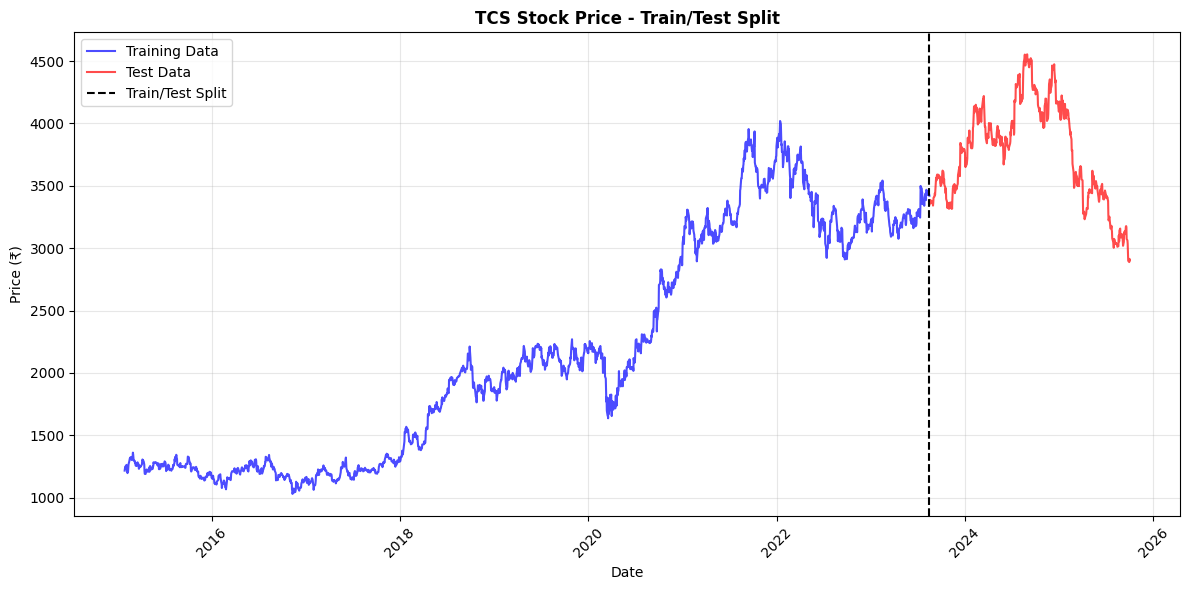

In [5]:
# Split data using time series approach (important for time series data)
print("Splitting data for time series modeling...")

# Use 80% for training, 20% for testing (chronological split)
split_index = int(len(modeling_data) * 0.8)

X_train = X[:split_index]
X_test = X[split_index:]
y_train = y[:split_index]
y_test = y[split_index:]

train_dates = modeling_data['Date'][:split_index]
test_dates = modeling_data['Date'][split_index:]

print(f"Training set: {len(X_train)} samples")
print(f"Test set: {len(X_test)} samples")
print(f"Training period: {train_dates.min()} to {train_dates.max()}")
print(f"Test period: {test_dates.min()} to {test_dates.max()}")

# Scale features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data scaling completed!")

# Display train/test split visualization
plt.figure(figsize=(12, 6))
plt.plot(train_dates, y_train, label='Training Data', color='blue', alpha=0.7)
plt.plot(test_dates, y_test, label='Test Data', color='red', alpha=0.7)
plt.axvline(x=train_dates.iloc[-1], color='black', linestyle='--', label='Train/Test Split')
plt.title('TCS Stock Price - Train/Test Split', fontweight='bold')
plt.xlabel('Date')
plt.ylabel('Price (₹)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [6]:
# Train multiple linear regression models
print("Training Linear Regression Models...")

# Dictionary to store models and results
models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=1.0)
}

results = {}

# Train and evaluate each model
for name, model in models.items():
    print(f"\nTraining {name}...")
    
    # Train the model
    model.fit(X_train_scaled, y_train)
    
    # Make predictions
    y_train_pred = model.predict(X_train_scaled)
    y_test_pred = model.predict(X_test_scaled)
    
    # Calculate metrics
    train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
    test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))
    train_mae = mean_absolute_error(y_train, y_train_pred)
    test_mae = mean_absolute_error(y_test, y_test_pred)
    train_r2 = r2_score(y_train, y_train_pred)
    test_r2 = r2_score(y_test, y_test_pred)
    
    # Store results
    results[name] = {
        'model': model,
        'train_pred': y_train_pred,
        'test_pred': y_test_pred,
        'train_rmse': train_rmse,
        'test_rmse': test_rmse,
        'train_mae': train_mae,
        'test_mae': test_mae,
        'train_r2': train_r2,
        'test_r2': test_r2
    }
    
    print(f"  Training RMSE: {train_rmse:.2f}")
    print(f"  Test RMSE: {test_rmse:.2f}")
    print(f"  Training R²: {train_r2:.4f}")
    print(f"  Test R²: {test_r2:.4f}")

# Create comparison table
comparison_data = []
for name, result in results.items():
    comparison_data.append({
        'Model': name,
        'Train_RMSE': result['train_rmse'],
        'Test_RMSE': result['test_rmse'],
        'Train_MAE': result['train_mae'],
        'Test_MAE': result['test_mae'],
        'Train_R²': result['train_r2'],
        'Test_R²': result['test_r2']
    })

comparison_df = pd.DataFrame(comparison_data)
print(f"\n=== MODEL COMPARISON ===")
print(comparison_df.round(4))

Training Linear Regression Models...

Training Linear Regression...
  Training RMSE: 35.70
  Test RMSE: 53.84
  Training R²: 0.9984
  Test R²: 0.9824

Training Ridge Regression...
  Training RMSE: 36.60
  Test RMSE: 56.12
  Training R²: 0.9983
  Test R²: 0.9809

Training Lasso Regression...
  Training RMSE: 36.34
  Test RMSE: 54.87
  Training R²: 0.9983
  Test R²: 0.9817

=== MODEL COMPARISON ===
               Model  Train_RMSE  Test_RMSE  Train_MAE  Test_MAE  Train_R²  \
0  Linear Regression     35.7009    53.8365    24.8510   39.0963    0.9984   
1   Ridge Regression     36.6039    56.1209    25.8204   40.9562    0.9983   
2   Lasso Regression     36.3428    54.8692    25.2497   39.5858    0.9983   

   Test_R²  
0   0.9824  
1   0.9809  
2   0.9817  


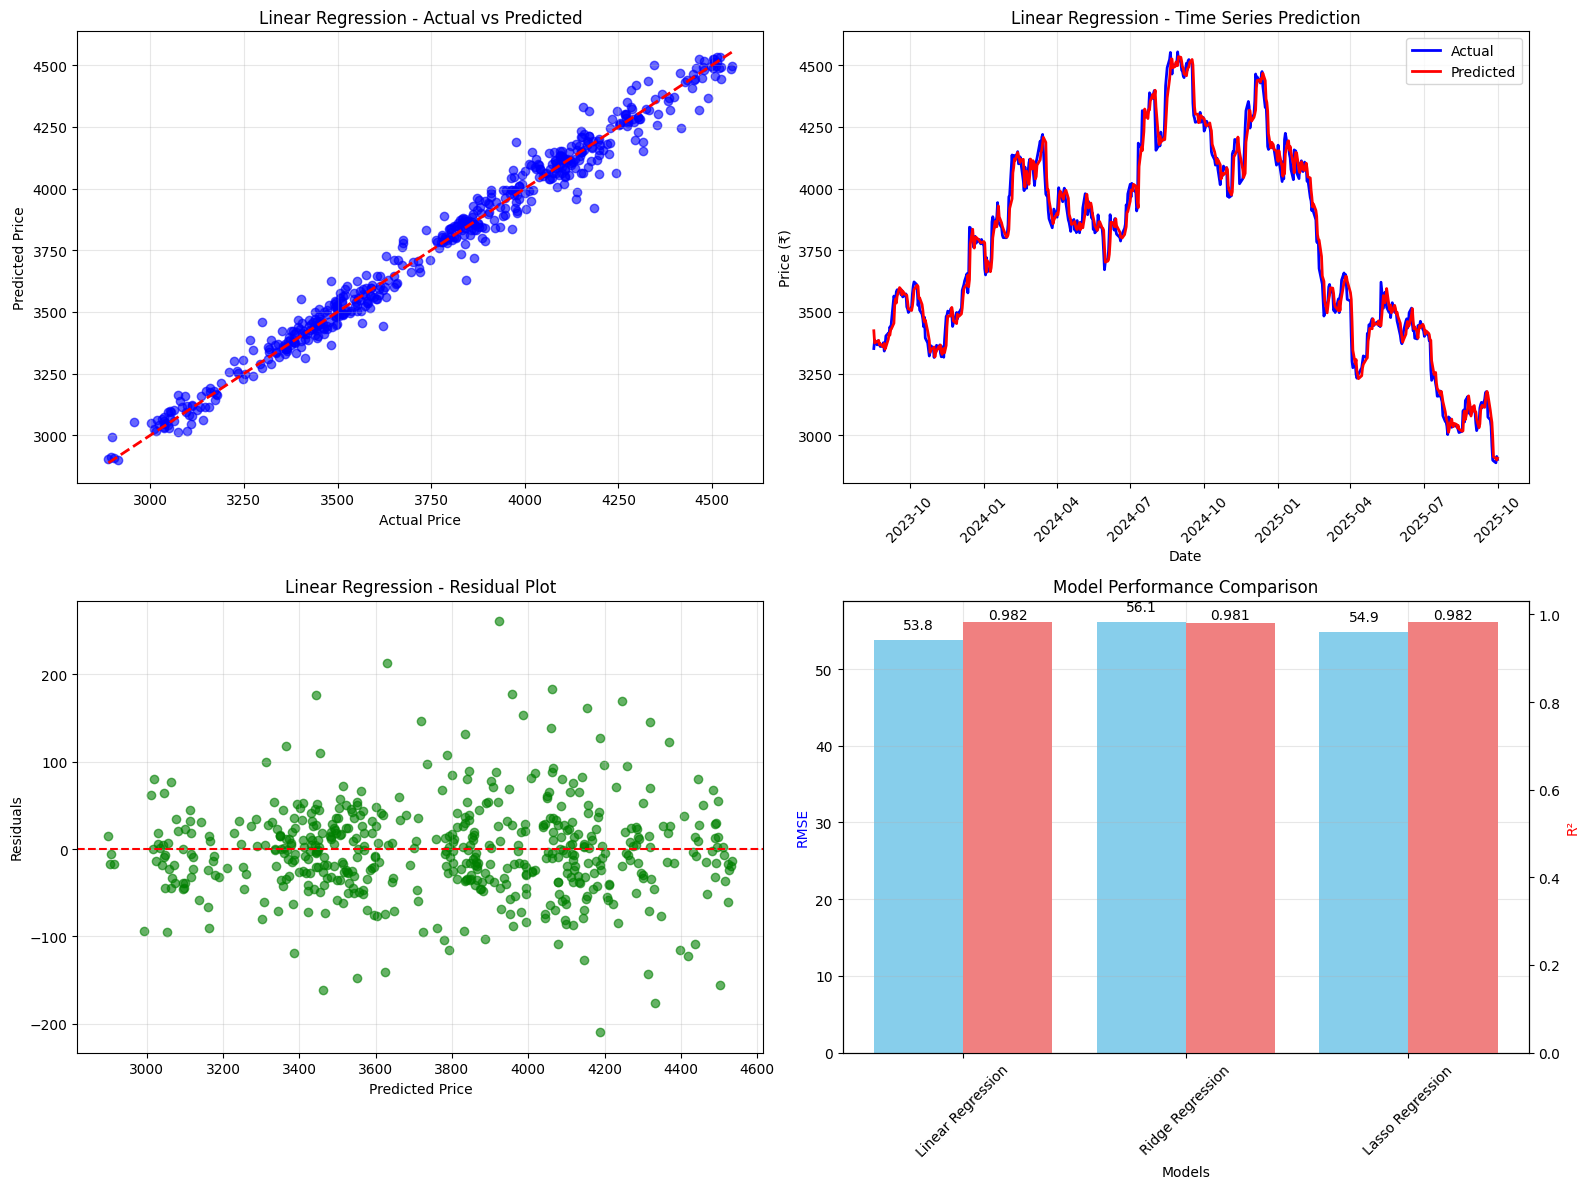


=== LINEAR REGRESSION MODEL ANALYSIS ===
Best performing model: Linear Regression
Test RMSE: 53.84
Test R²: 0.9824
Mean Absolute Error: 39.10
Percentage Error: 1.43%


In [7]:
# Visualize model predictions
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Actual vs Predicted for best model (Linear Regression)
best_model = 'Linear Regression'
ax1 = axes[0, 0]
ax1.scatter(y_test, results[best_model]['test_pred'], alpha=0.6, color='blue')
ax1.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
ax1.set_xlabel('Actual Price')
ax1.set_ylabel('Predicted Price')
ax1.set_title(f'{best_model} - Actual vs Predicted')
ax1.grid(True, alpha=0.3)

# Plot 2: Time series prediction
ax2 = axes[0, 1]
ax2.plot(test_dates.values, y_test.values, label='Actual', color='blue', linewidth=2)
ax2.plot(test_dates.values, results[best_model]['test_pred'], label='Predicted', color='red', linewidth=2)
ax2.set_xlabel('Date')
ax2.set_ylabel('Price (₹)')
ax2.set_title(f'{best_model} - Time Series Prediction')
ax2.legend()
ax2.grid(True, alpha=0.3)
ax2.tick_params(axis='x', rotation=45)

# Plot 3: Residuals
ax3 = axes[1, 0]
residuals = y_test.values - results[best_model]['test_pred']
ax3.scatter(results[best_model]['test_pred'], residuals, alpha=0.6, color='green')
ax3.axhline(y=0, color='red', linestyle='--')
ax3.set_xlabel('Predicted Price')
ax3.set_ylabel('Residuals')
ax3.set_title(f'{best_model} - Residual Plot')
ax3.grid(True, alpha=0.3)

# Plot 4: Model comparison
ax4 = axes[1, 1]
model_names = list(results.keys())
test_rmse_values = [results[name]['test_rmse'] for name in model_names]
test_r2_values = [results[name]['test_r2'] for name in model_names]

x_pos = np.arange(len(model_names))
ax4_twin = ax4.twinx()

bars1 = ax4.bar(x_pos - 0.2, test_rmse_values, 0.4, label='Test RMSE', color='skyblue')
bars2 = ax4_twin.bar(x_pos + 0.2, test_r2_values, 0.4, label='Test R²', color='lightcoral')

ax4.set_xlabel('Models')
ax4.set_ylabel('RMSE', color='blue')
ax4_twin.set_ylabel('R²', color='red')
ax4.set_title('Model Performance Comparison')
ax4.set_xticks(x_pos)
ax4.set_xticklabels(model_names, rotation=45)
ax4.grid(True, alpha=0.3)

# Add value labels on bars
for i, (bar1, bar2) in enumerate(zip(bars1, bars2)):
    ax4.text(bar1.get_x() + bar1.get_width()/2, bar1.get_height() + 1,
             f'{test_rmse_values[i]:.1f}', ha='center', va='bottom')
    ax4_twin.text(bar2.get_x() + bar2.get_width()/2, bar2.get_height() + 0.001,
                  f'{test_r2_values[i]:.3f}', ha='center', va='bottom')

plt.tight_layout()
plt.show()

print(f"\n=== LINEAR REGRESSION MODEL ANALYSIS ===")
print(f"Best performing model: {best_model}")
print(f"Test RMSE: {results[best_model]['test_rmse']:.2f}")
print(f"Test R²: {results[best_model]['test_r2']:.4f}")
print(f"Mean Absolute Error: {results[best_model]['test_mae']:.2f}")

# Calculate percentage error
mean_price = y_test.mean()
percentage_error = (results[best_model]['test_rmse'] / mean_price) * 100
print(f"Percentage Error: {percentage_error:.2f}%")